In [73]:
#Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Display plots inside notebook
%matplotlib inline

# Make plots larger
#Sets the default size of all plots.
#Width = 10 inches
#Height = 6 inches
plt.rcParams['figure.figsize'] = (10,6)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [74]:
#Load Dataset

df = pd.read_csv("dataset/netflix_titles.csv")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [75]:
#Display Basic Information

print("Shape of Dataset:")
print(df.shape)

print("\nRows:", df.shape[0])
print("Columns:", df.shape[1])

Shape of Dataset:
(8807, 12)

Rows: 8807
Columns: 12


In [76]:
#Column Names

df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [77]:
#Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [78]:
#Check Missing Values

df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [79]:
#Summary Statistics

df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [80]:
#Check Duplicate Records
df.duplicated().sum()

np.int64(0)

In [81]:
#Remove Duplicate Records
df.drop_duplicates(inplace=True)

print("Duplicates Removed")

Duplicates Removed


In [82]:
#Handle Missing Values
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Not Available")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna(df["rating"].mode()[0])

In [83]:
#Convert Date
# Remove leading and trailing spaces
df["date_added"] = df["date_added"].str.strip()

# Convert to datetime
#If a value is invalid or missing, Pandas converts it to NaT (Not a Time) instead of stopping the program with an error.
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Not Available,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Not Available,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [18]:
#Check Missing Values Again

df.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64

In [19]:
#Save Clean Dataset

df.to_csv("dataset/netflix_cleaned.csv", index=False)

print("Dataset Saved Successfully")

Dataset Saved Successfully


In [20]:
#Dataset Overview

print("Number of Rows :", df.shape[0])
print("Number of Columns :", df.shape[1])

df.head()

Number of Rows : 8807
Number of Columns : 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Not Available,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Not Available,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [21]:
#Data Types

df.dtypes

show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
dtype: object

In [22]:
#Movies vs TV Shows
df["type"].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

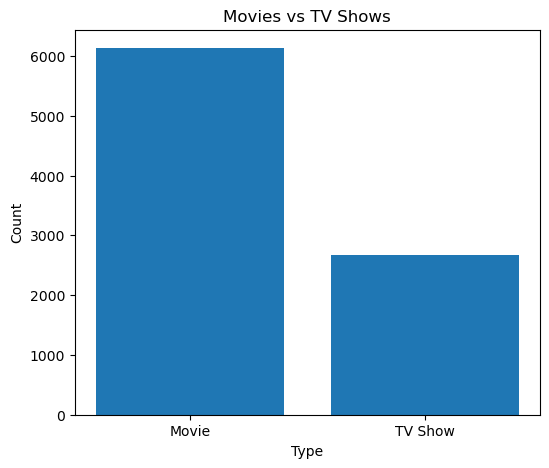

In [23]:
#Visualize Movies vs TV Shows
type_counts = df["type"].value_counts()

plt.figure(figsize=(6,5))
plt.bar(type_counts.index, type_counts.values)

plt.title("Movies vs TV Shows")
plt.xlabel("Type")
plt.ylabel("Count")

plt.show()

In [24]:
#Percentage of Movies and TV Shows
df["type"].value_counts(normalize=True) * 100

type
Movie      69.615079
TV Show    30.384921
Name: proportion, dtype: float64

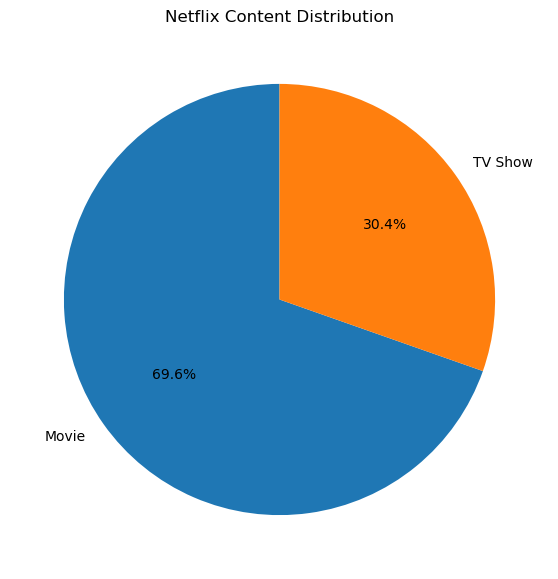

In [25]:
#Pie Chart
type_counts = df["type"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(type_counts,
        labels=type_counts.index,
        autopct="%1.1f%%",
        startangle=90)

plt.title("Netflix Content Distribution")

plt.show()

In [26]:
#Top 10 Countries
country = df["country"].value_counts().head(10)

country

country
United States     2818
India              972
Unknown            831
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64

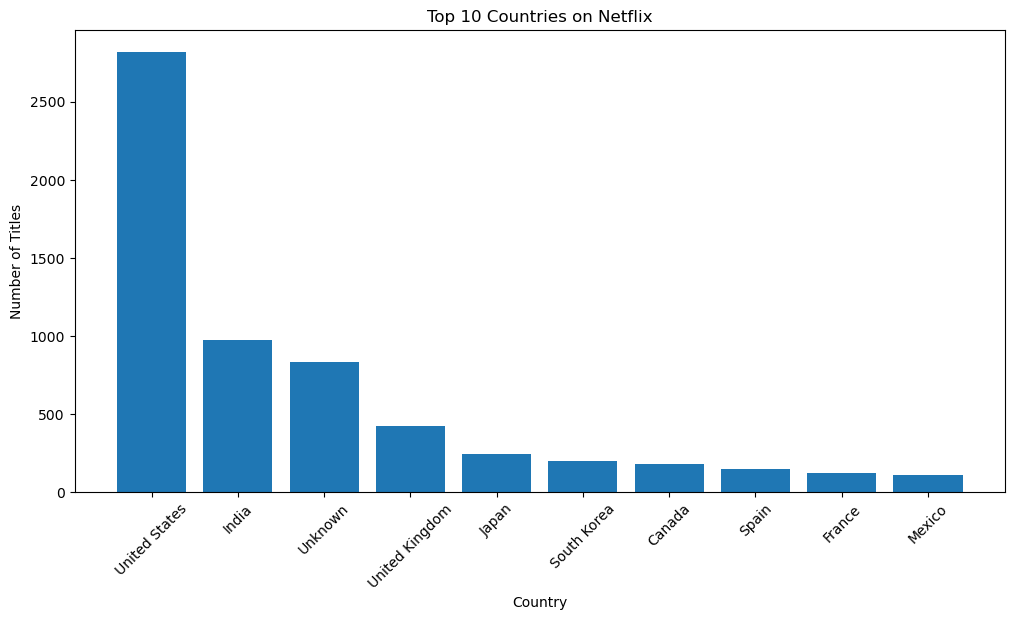

In [27]:
#Top 10 Countries Bar Chart
plt.figure(figsize=(12,6))

plt.bar(country.index, country.values)

plt.title("Top 10 Countries on Netflix")

plt.xlabel("Country")

plt.ylabel("Number of Titles")

plt.xticks(rotation=45)

plt.show()

In [28]:
#Content Ratings
rating = df["rating"].value_counts()

rating

rating
TV-MA       3211
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

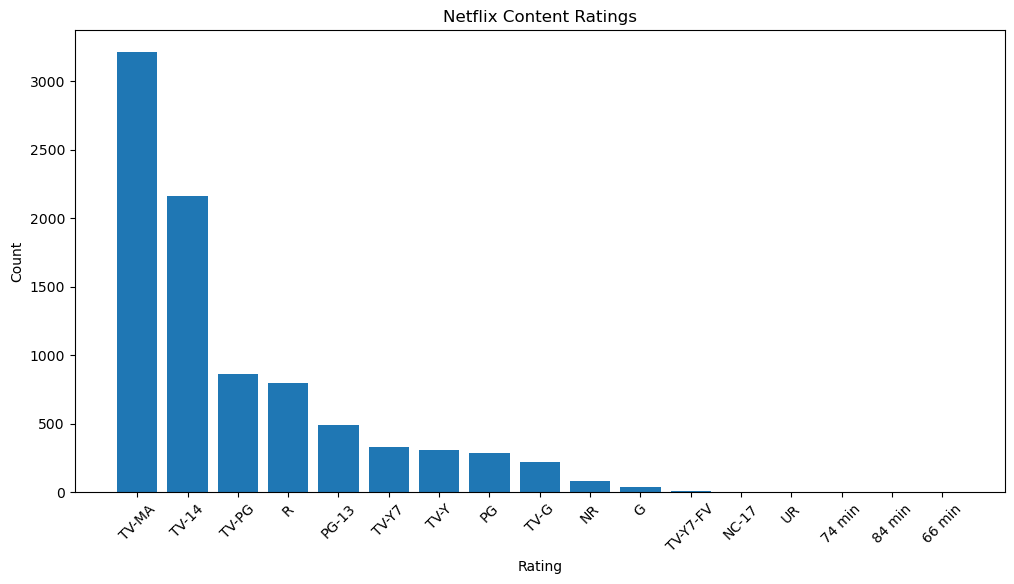

In [29]:
#Rating Distribution
plt.figure(figsize=(12,6))

plt.bar(rating.index, rating.values)

plt.title("Netflix Content Ratings")

plt.xlabel("Rating")

plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

In [30]:
#Top 10 Genres
genres = df["listed_in"].str.split(", ").explode()

top_genres = genres.value_counts().head(10)

top_genres

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

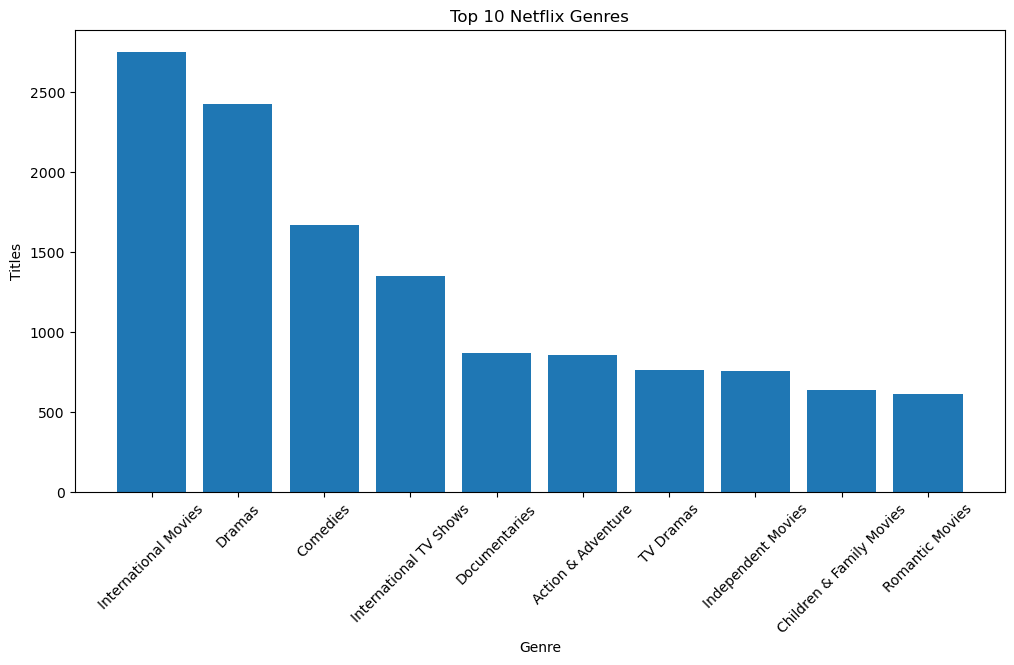

In [31]:
#Top Genres Visualization
plt.figure(figsize=(12,6))

plt.bar(top_genres.index, top_genres.values)

plt.title("Top 10 Netflix Genres")

plt.xlabel("Genre")

plt.ylabel("Titles")

plt.xticks(rotation=45)

plt.show()

In [32]:
#Top 10 Directors
top_directors = df[df["director"] != "Unknown"]["director"].value_counts().head(10)

top_directors

director
Rajiv Chilaka             19
Raúl Campos, Jan Suter    18
Marcus Raboy              16
Suhas Kadav               16
Jay Karas                 14
Cathy Garcia-Molina       13
Martin Scorsese           12
Youssef Chahine           12
Jay Chapman               12
Steven Spielberg          11
Name: count, dtype: int64

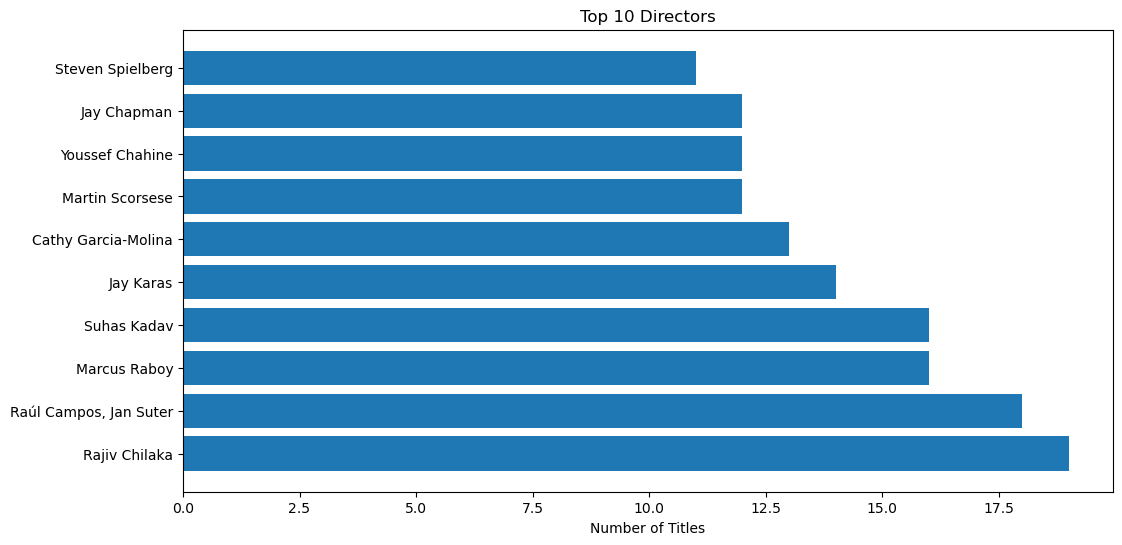

In [33]:
#Directors Chart
plt.figure(figsize=(12,6))

plt.barh(top_directors.index, top_directors.values)

plt.title("Top 10 Directors")

plt.xlabel("Number of Titles")

plt.show()

In [34]:
#Number of Titles Released Each Year

release_year = df["release_year"].value_counts().sort_index()

release_year.head()

release_year
1925    1
1942    2
1943    3
1944    3
1945    4
Name: count, dtype: int64

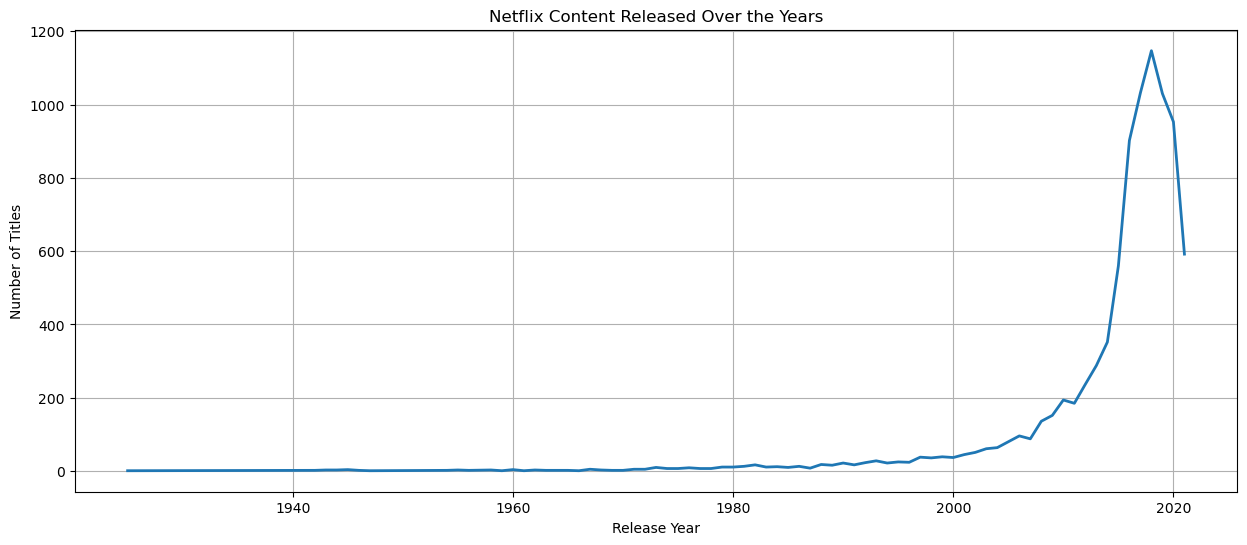

In [35]:
#Line Chart - Netflix Content Growth
plt.figure(figsize=(15,6))

plt.plot(release_year.index, release_year.values, linewidth=2)

plt.title("Netflix Content Released Over the Years")

plt.xlabel("Release Year")

plt.ylabel("Number of Titles")

plt.grid(True)

plt.show()

In [36]:
#Top 10 Release Years
top_years = df["release_year"].value_counts().head(10)

top_years

release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64

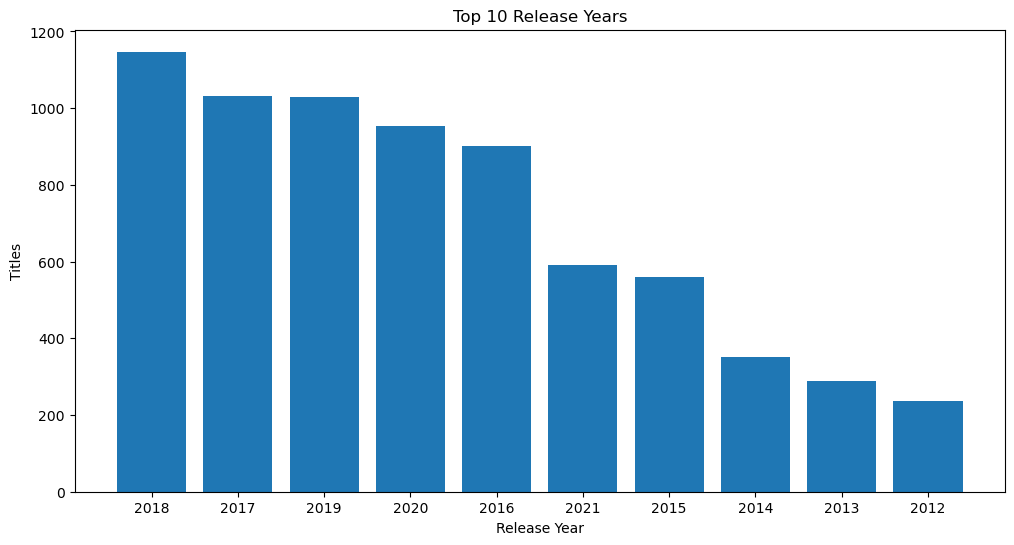

In [37]:
#Bar Chart of Top Release Years
plt.figure(figsize=(12,6))

plt.bar(top_years.index.astype(str), top_years.values)

plt.title("Top 10 Release Years")

plt.xlabel("Release Year")

plt.ylabel("Titles")

plt.show()

In [38]:
#Movies Released Every Year
movies = df[df["type"] == "Movie"]

movie_year = movies["release_year"].value_counts().sort_index()

movie_year.head()

release_year
1942    2
1943    3
1944    3
1945    3
1946    1
Name: count, dtype: int64

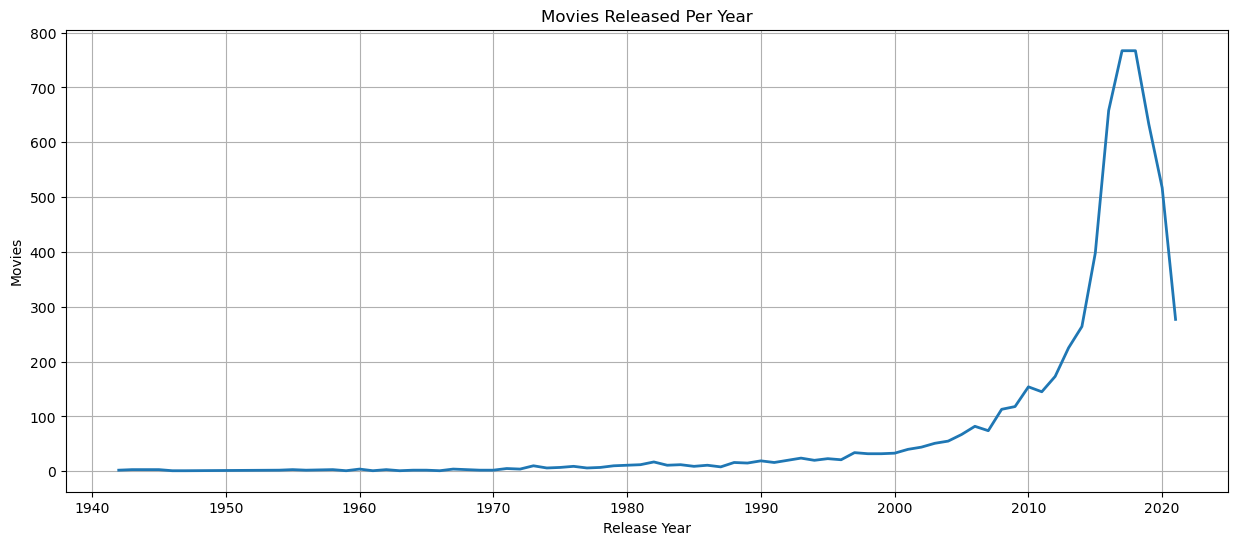

In [39]:
#Movies Trend
plt.figure(figsize=(15,6))

plt.plot(movie_year.index, movie_year.values, linewidth=2)

plt.title("Movies Released Per Year")

plt.xlabel("Release Year")

plt.ylabel("Movies")

plt.grid(True)

plt.show()

In [40]:
#TV Shows Released Every Year
tv = df[df["type"] == "TV Show"]

tv_year = tv["release_year"].value_counts().sort_index()

tv_year.head()

release_year
1925    1
1945    1
1946    1
1963    1
1967    1
Name: count, dtype: int64

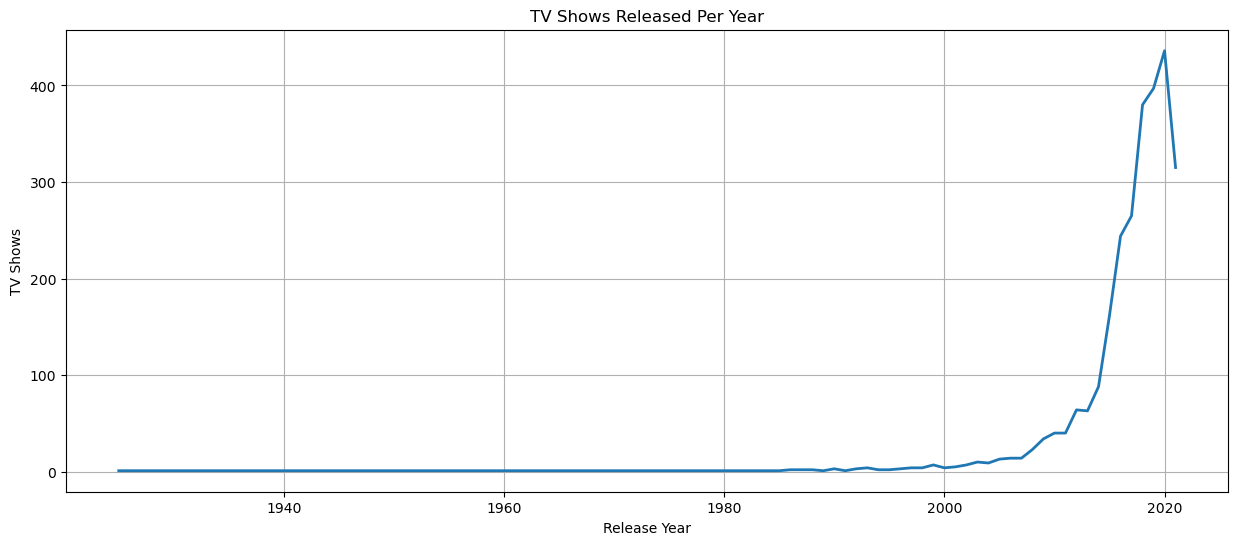

In [41]:
#TV Shows Trend
plt.figure(figsize=(15,6))

plt.plot(tv_year.index, tv_year.values, linewidth=2)

plt.title("TV Shows Released Per Year")

plt.xlabel("Release Year")

plt.ylabel("TV Shows")

plt.grid(True)

plt.show()

In [42]:
#Compare Movies and TV Shows
comparison = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)

comparison.tail()

type,Movie,TV Show
release_year,,
2017,767,265
2018,767,380
2019,633,397
2020,517,436
2021,277,315


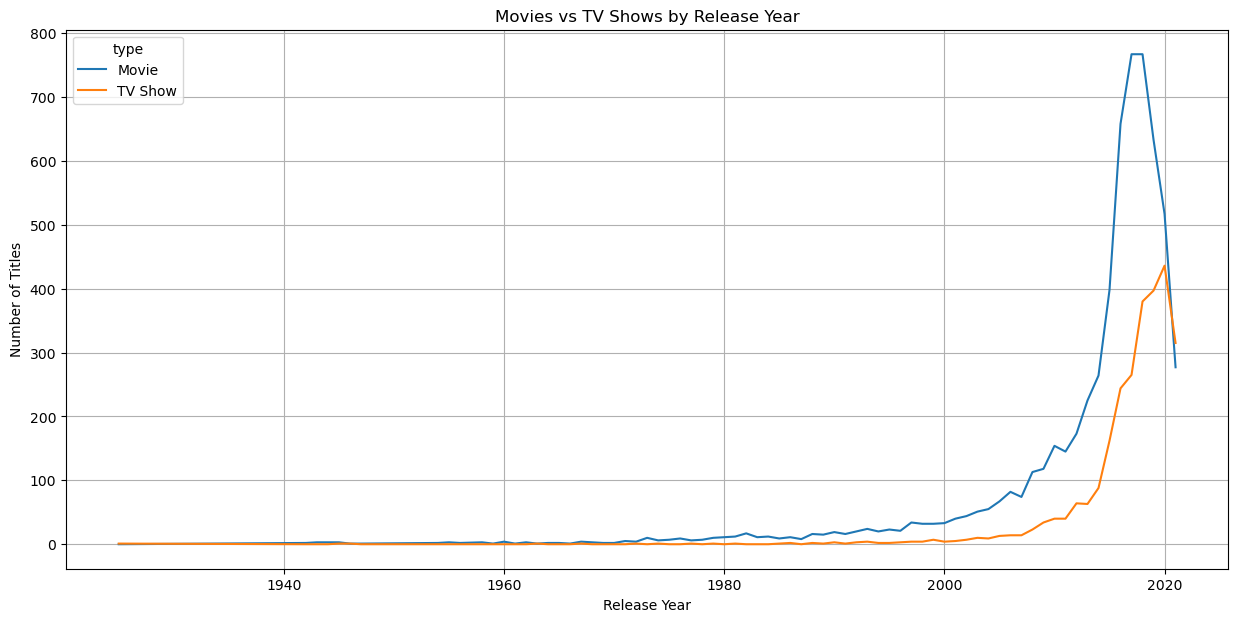

In [43]:
#Comparison Chart
comparison.plot(figsize=(15,7))

plt.title("Movies vs TV Shows by Release Year")

plt.xlabel("Release Year")

plt.ylabel("Number of Titles")

plt.grid(True)

plt.show()

In [44]:
import numpy as np

In [45]:
#Basic Statistics
years = df["release_year"].to_numpy()

print("Mean :", np.mean(years))
print("Median :", np.median(years))
print("Minimum :", np.min(years))
print("Maximum :", np.max(years))
print("Variance :", np.var(years))
print("Standard Deviation :", np.std(years))

Mean : 2014.1801975701146
Median : 2017.0
Minimum : 1925
Maximum : 2021
Variance : 77.77143481960121
Standard Deviation : 8.818811417623195


In [46]:
#Percentiles
print("25th Percentile :", np.percentile(years, 25))
print("50th Percentile :", np.percentile(years, 50))
print("75th Percentile :", np.percentile(years, 75))

25th Percentile : 2013.0
50th Percentile : 2017.0
75th Percentile : 2019.0


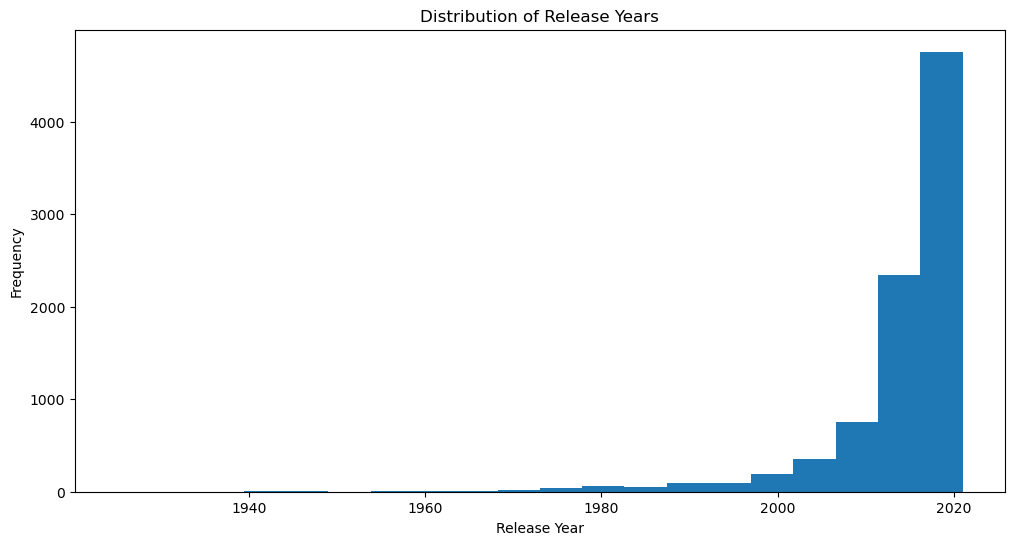

In [47]:
#Histogram
plt.figure(figsize=(12,6))

plt.hist(years, bins=20)

plt.title("Distribution of Release Years")

plt.xlabel("Release Year")

plt.ylabel("Frequency")

plt.show()

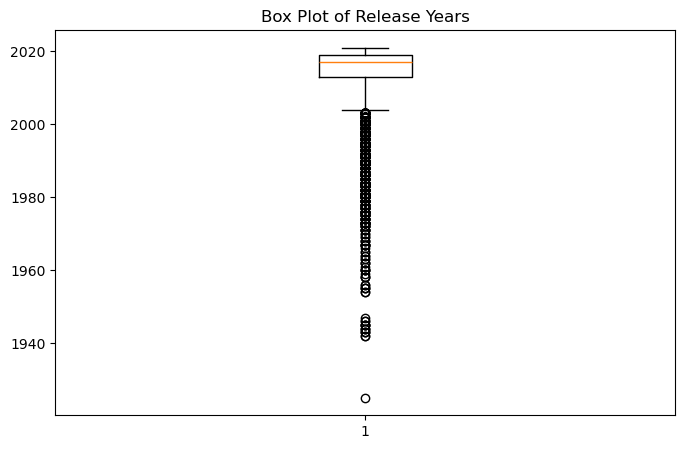

In [48]:
#Box Plot
plt.figure(figsize=(8,5))

plt.boxplot(years)

plt.title("Box Plot of Release Years")

plt.show()

In [49]:
from scipy import stats

In [50]:
#Check if Release Year is Normally Distributed
release_year = df["release_year"].dropna()

stat, p = stats.shapiro(release_year.sample(500, random_state=42))

print("Shapiro-Wilk Test")
print("Statistic =", stat)
print("P-value =", p)

if p > 0.05:
    print("Data is Normally Distributed")
else:
    print("Data is NOT Normally Distributed")

Shapiro-Wilk Test
Statistic = 0.5954029918985058
P-value = 1.7108586534469004e-32
Data is NOT Normally Distributed


In [51]:
#Average Release Year of Movies vs TV Shows
movies = df[df["type"] == "Movie"]["release_year"]
tvshows = df[df["type"] == "TV Show"]["release_year"]

print("Average Movie Release Year:", movies.mean())
print("Average TV Show Release Year:", tvshows.mean())

Average Movie Release Year: 2013.1215136193116
Average TV Show Release Year: 2016.605754857997


In [52]:
#Independent t-test
t_stat, p_value = stats.ttest_ind(movies, tvshows, equal_var=False)

print("T-Test Result")
print("T-statistic =", t_stat)
print("P-value =", p_value)

if p_value < 0.05:
    print("There is a significant difference.")
else:
    print("There is no significant difference.")

T-Test Result
T-statistic = -20.976297477593885
P-value = 3.711540080449863e-95
There is a significant difference.


In [53]:
#Chi-Square Test (Type vs Rating)
contingency_table = pd.crosstab(df["type"], df["rating"])

chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p)
print("Degrees of Freedom:", dof)

if p < 0.05:
    print("Type and Rating are associated.")
else:
    print("No significant association.")

Chi-Square Statistic: 1047.8627809180348
P-value: 6.277819254424652e-213
Degrees of Freedom: 16
Type and Rating are associated.


In [54]:
#Extract Movie Duration
movie_duration = df[df["type"] == "Movie"].copy()

movie_duration["duration_min"] = (
    movie_duration["duration"]
    .str.replace(" min", "", regex=False)
)

movie_duration["duration_min"] = pd.to_numeric(
    movie_duration["duration_min"],
    errors="coerce"
)

movie_duration.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_min
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Not Available,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90.0
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",Unknown,2021-09-24,2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...,91.0
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s...",125.0
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,2021-09-24,2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...,104.0
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic",2021-09-23,2021,TV-MA,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...,127.0


In [55]:
#Duration Statistics
print("Average Duration:", movie_duration["duration_min"].mean())

print("Maximum Duration:", movie_duration["duration_min"].max())

print("Minimum Duration:", movie_duration["duration_min"].min())

Average Duration: 99.57718668407311
Maximum Duration: 312.0
Minimum Duration: 3.0


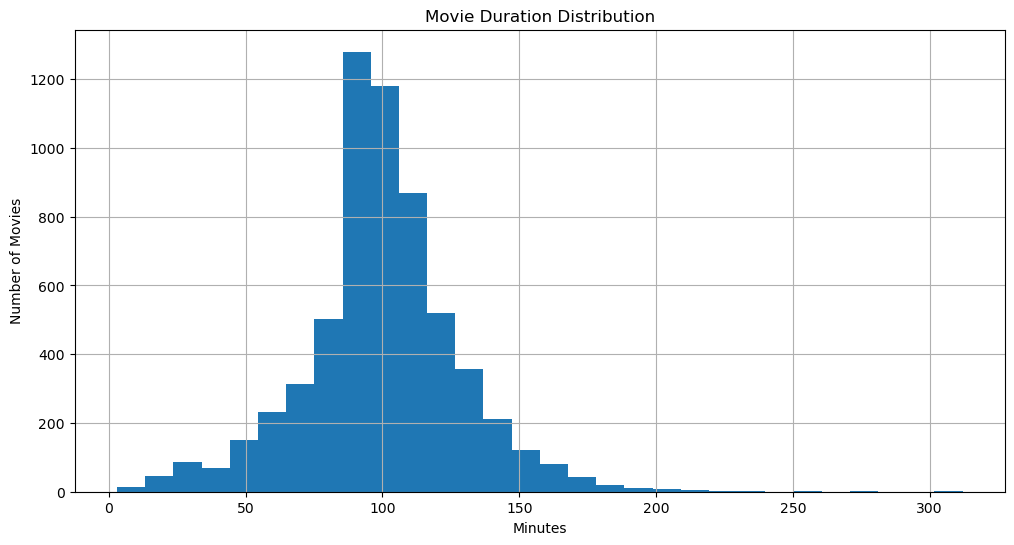

In [56]:
#Histogram of Movie Duration
plt.figure(figsize=(12,6))

plt.hist(movie_duration["duration_min"].dropna(), bins=30)

plt.title("Movie Duration Distribution")

plt.xlabel("Minutes")

plt.ylabel("Number of Movies")

plt.grid(True)

plt.show()

In [57]:
#Top 10 Longest Movies
longest_movies = movie_duration.nlargest(
    10,
    "duration_min"
)[["title", "duration_min"]]

longest_movies

,title,duration_min
4253,Black Mirror: Bandersnatch,312.0
717,Headspace: Unwind Your Mind,273.0
2491,The School of Mischief,253.0
2487,No Longer kids,237.0
2484,Lock Your Girls In,233.0
2488,Raya and Sakina,230.0
166,Once Upon a Time in America,229.0
7932,Sangam,228.0
1019,Lagaan,224.0
4573,Jodhaa Akbar,214.0


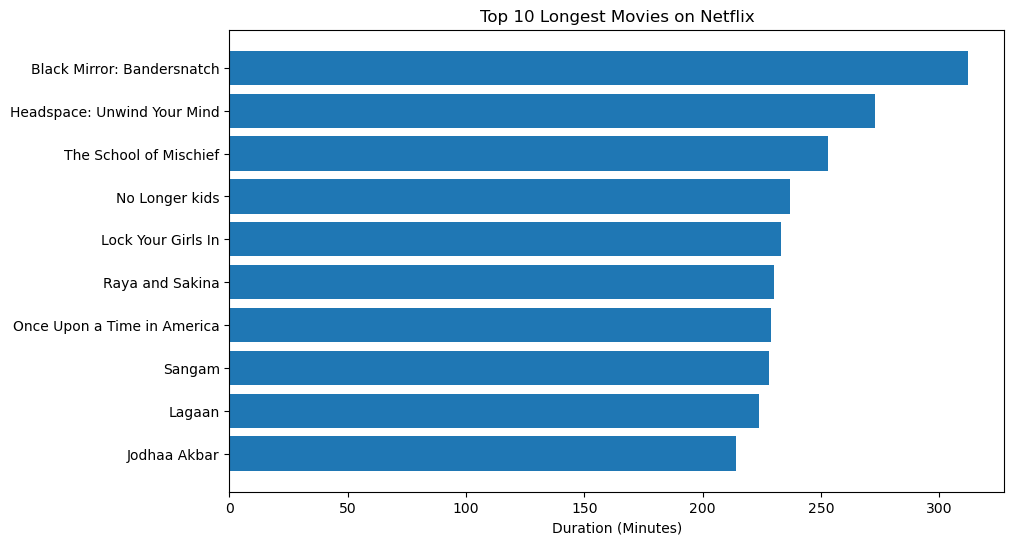

In [58]:
#Longest Movies Chart
plt.figure(figsize=(10,6))

plt.barh(
    longest_movies["title"],
    longest_movies["duration_min"]
)

plt.title("Top 10 Longest Movies on Netflix")

plt.xlabel("Duration (Minutes)")

plt.gca().invert_yaxis()

plt.show()

In [59]:
#Extract Month
df["month_added"] = df["date_added"].dt.month_name()

df[["date_added", "month_added"]].head()

,date_added,month_added
0,2021-09-25,September
1,2021-09-24,September
2,2021-09-24,September
3,2021-09-24,September
4,2021-09-24,September


In [60]:
#Count by Month
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly = (
    df["month_added"]
    .value_counts()
    .reindex(month_order)
)

monthly

month_added
January      738
February     563
March        742
April        764
May          632
June         728
July         827
August       755
September    770
October      760
November     705
December     813
Name: count, dtype: int64

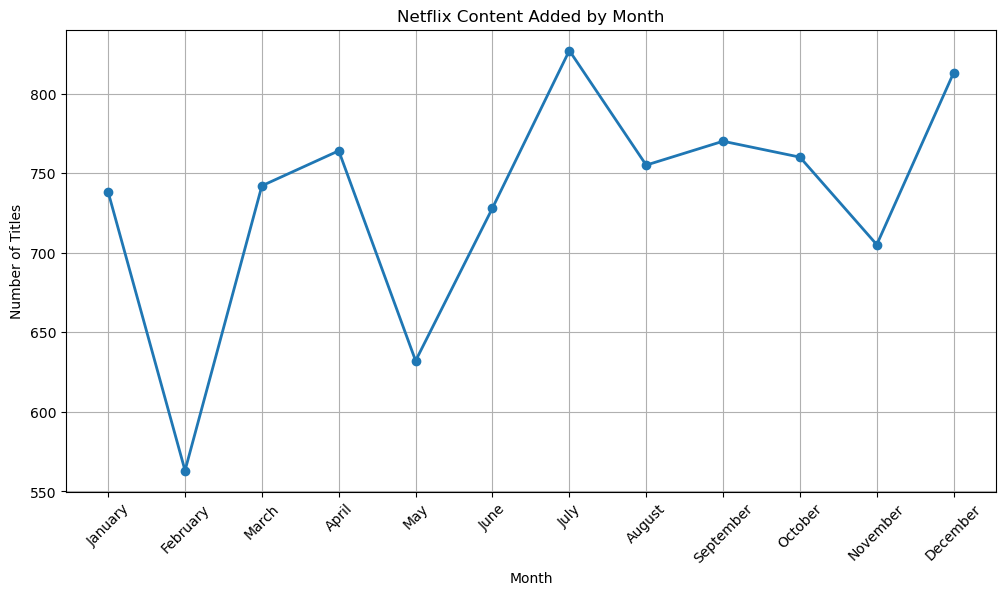

In [61]:
#Monthly Content Added Chart
plt.figure(figsize=(12,6))

plt.plot(
    monthly.index,
    monthly.values,
    marker="o",
    linewidth=2
)

plt.title("Netflix Content Added by Month")

plt.xlabel("Month")

plt.ylabel("Number of Titles")

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

In [63]:
#Export the Cleaned Dataset
df.to_csv("output/netflix_cleaned.csv", index=False)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.


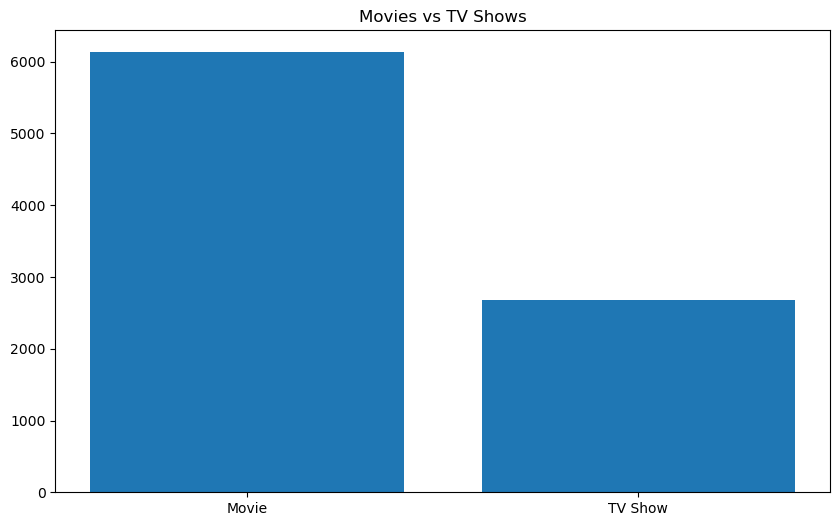

In [68]:
#Save High-Quality Charts

plt.figure(figsize=(10,6))

plt.bar(type_counts.index, type_counts.values)

plt.title("Movies vs TV Shows")

plt.savefig("output/movies_vs_tvshows.png", dpi=300)

plt.show()